# **Section 5: Logistic Regression**

In this notebook, I will train and evaluate logistic regressions. I will start with a baseline model using default parameters, and will then tune the regularization parameter (C) and the L1 ratio using a cross-validated grid search. Finally, I will look at which features contribute the most to predicting resistance, and save the results.

#### **Contents**
1. **Import data**
2. **Basic logistic regression**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Biomarker identification**
   - 5.1 Load cluster names
   - 5.2 Extract feature importance
   - 5.3 Export biomarkers
6. **Saving model results**


## **1. Importing the Data**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')
sns.set_palette("pastel")

In [2]:
# Load features and labels
sv_train = pd.read_csv("Data/sv_train_selected.csv", index_col=0)
sv_test = pd.read_csv("Data/sv_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = sv_train.values
y_train = profiles_train.values.ravel()

X_test = sv_test.values
y_test = profiles_test.values.ravel()

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (177, 199)
Test set shape: (50, 199)
Categories: [0 1]


## **2. Basic Logistic Regression**

### **2.1 Training and fitting the model**

Let's start with a basic logistic regression model using default parameters (C=1). I chose to use an elastic net regression (which combines L1 and L2 regularization) with a l1_ratio of 0.5.

In [3]:
logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=1.0, max_iter=1000, random_state=4)
)

# Train the model
logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,199
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


### **2.2 Evaluating the model**

In [4]:
# Evaluate on training and test sets
accuracy_train = logreg.score(X_train, y_train)
accuracy_test = logreg.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 0.9944
Accuracy test set: 0.5800


### **2.3 Classification report and confusion matrix**

In [5]:
# Get predictions
y_test_pred = logreg.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.43      0.55        30
           1       0.48      0.80      0.60        20

    accuracy                           0.58        50
   macro avg       0.62      0.62      0.58        50
weighted avg       0.65      0.58      0.57        50



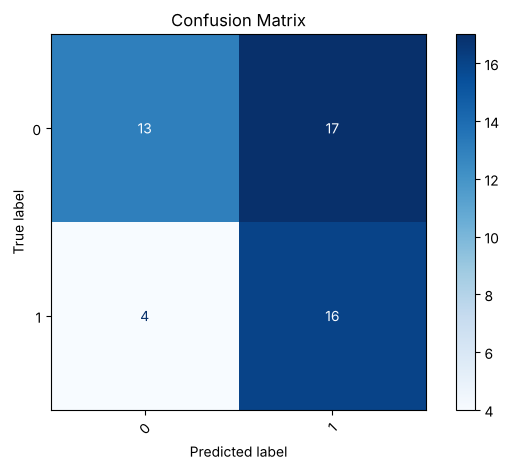

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=logreg.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## **3. Hyperparameter Tuning**

Let's use a cross-validated grid search to find the optimal regularization parameter C and L1 ratio.

### **3.1 Grid Search**

In [7]:
# Create Logistic Regression pipeline
logreg_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=1, penalty="elasticnet", solver="saga")
)

# Define parameter grid
param_grid = {
    "logisticregression__C": np.logspace(-2, 2, 5),
    "logisticregression__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0]
}

# Create grid search
grid_search = GridSearchCV(
    logreg_pipeline,
    param_grid,
    cv=4,
    return_train_score=True,
    n_jobs=-1
)

# Perform grid search
print("Performing grid search")
grid_search.fit(X_train, y_train)

print(f"\nBest parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

Performing grid search



Best parameters: {'logisticregression__C': np.float64(0.1), 'logisticregression__l1_ratio': 0.0}
Best cross-validation score: 0.8535


In [8]:
cv_results = pd.DataFrame(grid_search.cv_results_)

print(cv_results.loc[:,['mean_test_score', 'std_test_score',
    'mean_train_score', 'std_train_score',
    'param_logisticregression__C'
]].head())

   mean_test_score  std_test_score  mean_train_score  std_train_score  \
0         0.819823        0.067395          0.947240         0.009418   
1         0.581944        0.009585          0.581924         0.003176   
2         0.581944        0.009585          0.581924         0.003176   
3         0.581944        0.009585          0.581924         0.003176   
4         0.581944        0.009585          0.581924         0.003176   

   param_logisticregression__C  
0                         0.01  
1                         0.01  
2                         0.01  
3                         0.01  
4                         0.01  


### **3.2 Visualizing Training/Validation curves**

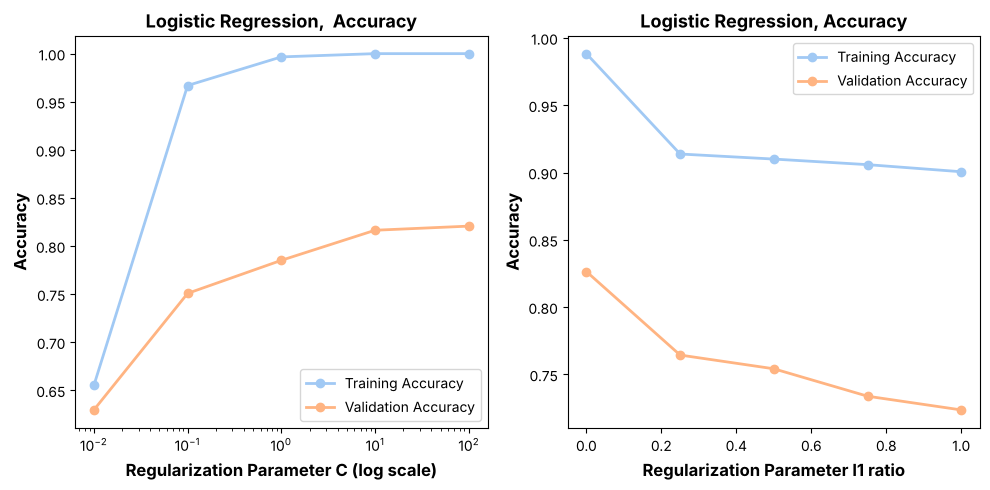

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10,5))

by_C = cv_results.groupby("param_logisticregression__C")[['mean_train_score', 'mean_test_score']].mean()
by_l1 = cv_results.groupby("param_logisticregression__l1_ratio")[['mean_train_score', 'mean_test_score']].mean()

axes[0].semilogx(by_C.index, by_C['mean_train_score'], label='Training Accuracy', marker='o', linewidth=2)
axes[0].semilogx(by_C.index, by_C['mean_test_score'], label='Validation Accuracy', marker='o', linewidth=2)
axes[0].set_xlabel('Regularization Parameter C (log scale)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[0].set_title('Logistic Regression,  Accuracy', fontsize=13, fontweight='bold')
axes[0].legend()

axes[1].plot(by_l1.index, by_l1['mean_train_score'], label='Training Accuracy', marker='o', linewidth=2)
axes[1].plot(by_l1.index, by_l1['mean_test_score'], label='Validation Accuracy', marker='o', linewidth=2)
axes[1].set_xlabel('Regularization Parameter l1 ratio', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
axes[1].set_title('Logistic Regression, Accuracy', fontsize=13, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig("Figures/05_logreg_training_curves.png", dpi=300, bbox_inches='tight')
plt.show()

## **4. Evaluate Best Model**

### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_logreg = grid_search.best_estimator_
accuracy_test_best = best_logreg.score(X_test, y_test)

print(f"\nBest model test accuracy: {accuracy_test_best:.4f}")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV score: {grid_search.best_score_:.4f}")


Best model test accuracy: 0.7000
Best parameters: {'logisticregression__C': np.float64(0.1), 'logisticregression__l1_ratio': 0.0}
Best CV score: 0.8535


### **4.2 Classification report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_logreg.predict(X_test)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_best))


Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.57      0.69        30
           1       0.58      0.90      0.71        20

    accuracy                           0.70        50
   macro avg       0.74      0.73      0.70        50
weighted avg       0.77      0.70      0.70        50



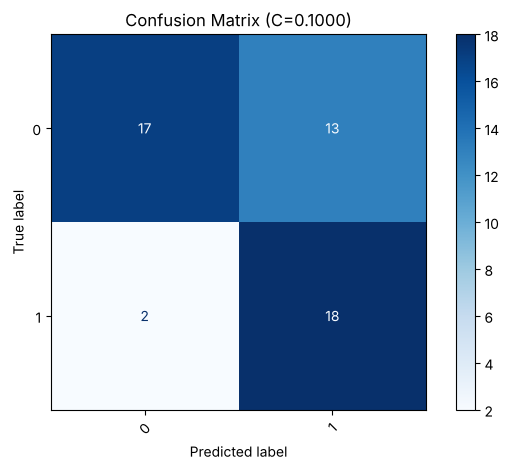

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_logreg.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_logreg.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix (C={grid_search.best_params_['logisticregression__C']:.4f})")
plt.tight_layout()
plt.savefig("Figures/05_logreg_cm.png", dpi=300, bbox_inches='tight')
plt.show()

### **4.3 ROC curve and AUC score**

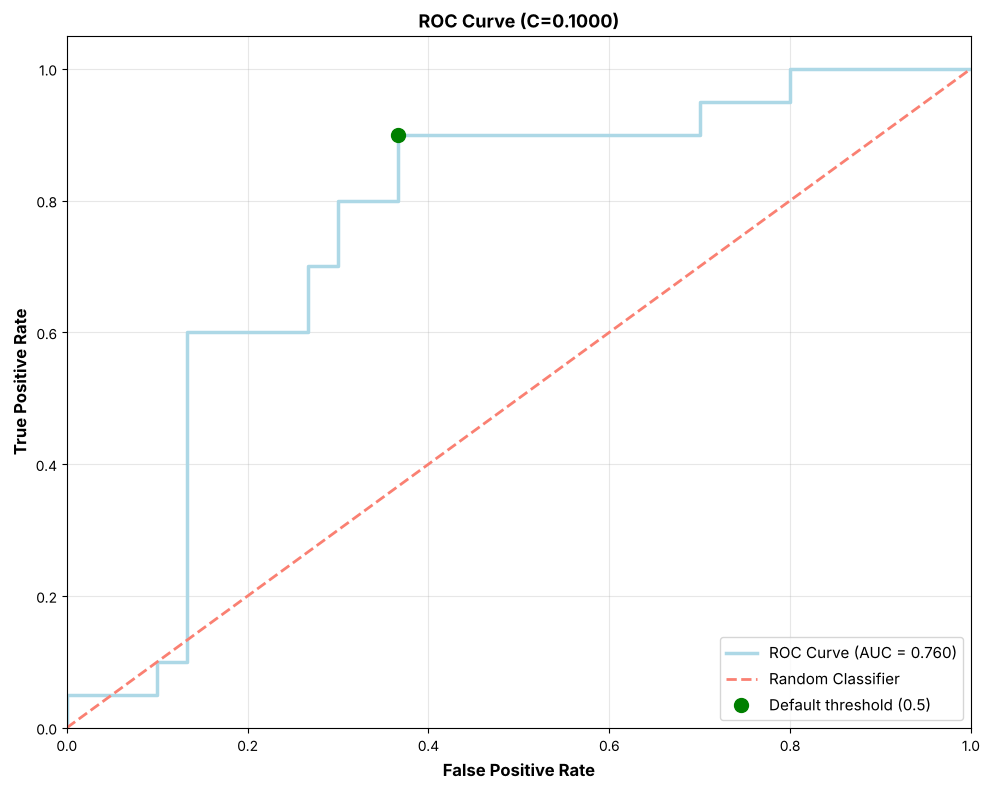


AUC Score: 0.7600
At default threshold (0.5):
True Positive Rate: 0.900 (detects 90.0% of resistants)
False Positive Rate: 0.367 (36.7% of susceptibles are misclassified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probability predictions for the positive class
y_test_proba = best_logreg.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='lightblue', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='salmon', lw=2, linestyle='--', label='Random Classifier')

# Mark 0.5 threshold
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold (0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve (C={grid_search.best_params_["logisticregression__C"]:.4f})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/05_logreg_ROC.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print(f"At default threshold (0.5):")
print(f"True Positive Rate: {tpr[default_idx]:.3f} (detects {tpr[default_idx]*100:.1f}% of resistants)")
print(f"False Positive Rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptibles are misclassified)")

## **5. Biomarker Identification**
Let's now have a look at which features contribute the most to the model.
We will identify biomarkers (features that contribute the most to the model) using **Model Weights**, by looking at the coefficients from the logistic regression model. A positive coefficient means that the presence of the SV is associated with resistance, a negative coefficient that it is associated with susceptibility.

### **5.1 Load feature names**
We now don't have access directly to the original features, as they were grouped into clusters in the third notebook. We do however have the cluster numbers (the column names of the feature matrix), and a list of the SVs in each cluster (with their SV type and length) in the file Data/clusters.csv.

In [14]:
cluster_names = sv_train.columns.astype(int).values
features_to_cluster = pd.read_csv("Data/clusters.csv")
features_to_cluster.head()

,cluster,feature,cluster_size,svtype,svlen
0,0,sv__NZ_CP009157.1_4016031_4016119_INV,1,INV,88
1,1,sv__NZ_CP009157.1_1200812_1200910_DEL,1,DEL,98
2,2,sv__NZ_CP009157.1_729822_729873_INV,1,INV,51
3,3,sv__NZ_CP009156.1_3103819_3103911_INV,1,INV,92
4,4,sv__NZ_CP009156.1_2702723_2702784_INV,1,INV,61


### **5.2 Computing feature importance**
Let's now see which clusters contribute the most to predicting resistance using the best model.

In [15]:
# Extract coefficients from the best model
coefficients = best_logreg.named_steps['logisticregression'].coef_[0]

# Create dataframe with cluster names and coefficients
coef_df = pd.DataFrame({
    'cluster': cluster_names,
    'coefficient': coefficients,
    'abs_coefficient': np.abs(coefficients)
})

# Sort by absolute coefficient value
coef_df = coef_df.sort_values('abs_coefficient', ascending=False)

print(f"\nTop 20 Clusters:")
print(coef_df.head(20)[['cluster', 'coefficient', 'abs_coefficient']].to_string(index=False))


Top 20 Clusters:
 cluster  coefficient  abs_coefficient
      69    -0.312074         0.312074
      47    -0.267778         0.267778
      75    -0.255066         0.255066
     193    -0.241499         0.241499
      46    -0.228455         0.228455
      74    -0.226645         0.226645
     161     0.225886         0.225886
     165    -0.219441         0.219441
     105    -0.214288         0.214288
      27    -0.209608         0.209608
     115    -0.208004         0.208004
      68    -0.207922         0.207922
     143    -0.206858         0.206858
       1    -0.203902         0.203902
     110    -0.195780         0.195780
      97     0.193201         0.193201
      99     0.187204         0.187204
     191    -0.185794         0.185794
       2    -0.183830         0.183830
      65    -0.183655         0.183655


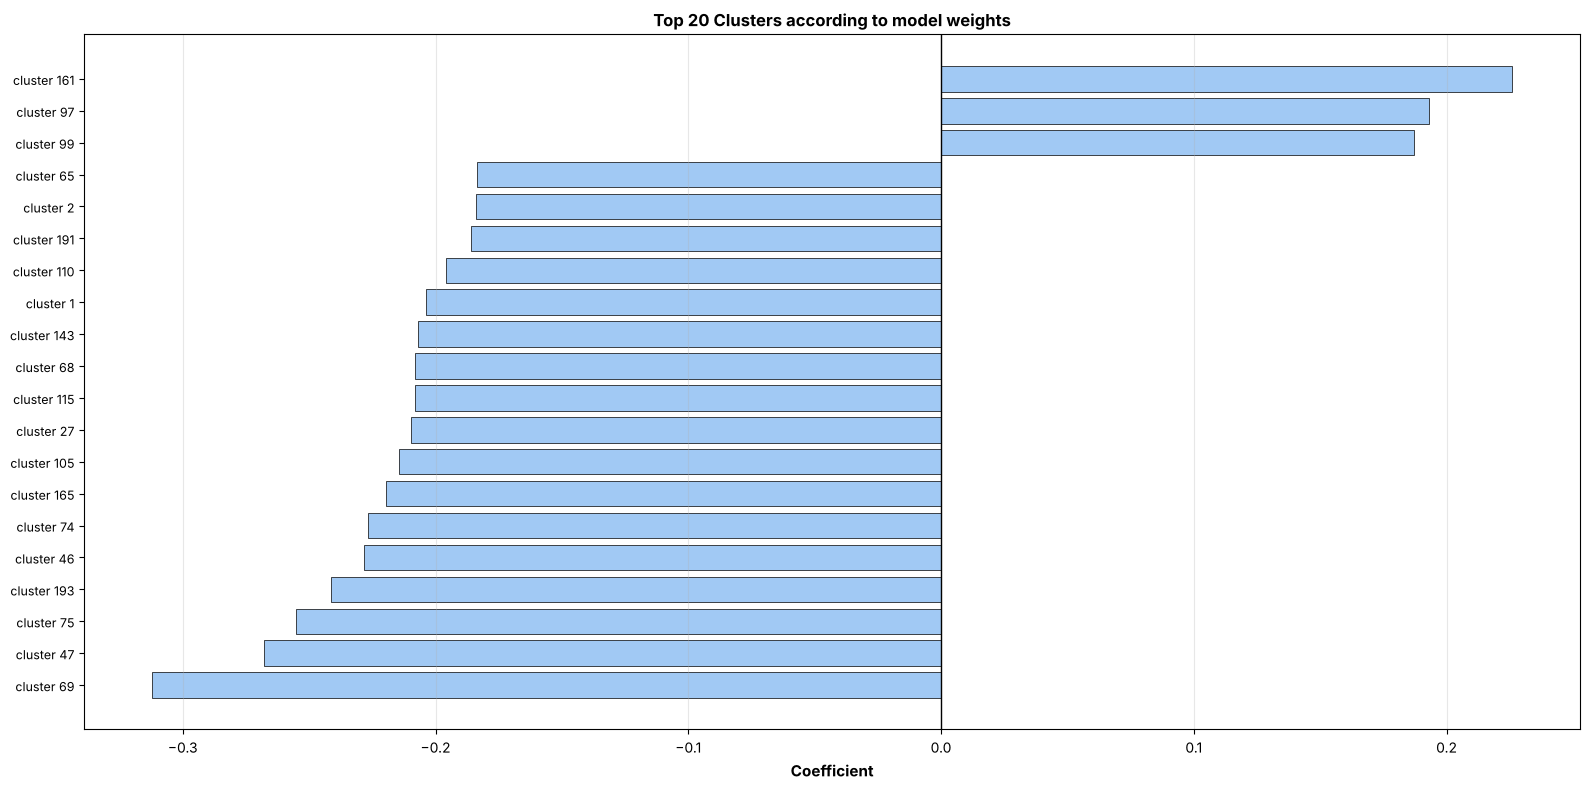

In [16]:
# Visualize top clusters by model weights
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

# Top 20 features by absolute coefficient
top_features = coef_df.head(20).sort_values("coefficient")
ax.barh(range(len(top_features)), top_features['coefficient'], edgecolor='black', linewidth=0.5)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels([f'cluster {c}' for c in top_features['cluster']], fontsize=9)
ax.set_xlabel('Coefficient', fontweight='bold', fontsize=11)
ax.set_title('Top 20 Clusters according to model weights', fontweight='bold', fontsize=12)
ax.axvline(0, color='black', linestyle='-', linewidth=1)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('Figures/05_logreg_biomarkers_weights.png', dpi=300, bbox_inches='tight')
plt.show()

We can now generate a list with all original SVs contributing to these clusters.

In [17]:
print(features_to_cluster[features_to_cluster.cluster.isin(top_features['cluster'])])

     cluster                                feature  cluster_size svtype  \
1          1  sv__NZ_CP009157.1_1200812_1200910_DEL             1    DEL   
2          2    sv__NZ_CP009157.1_729822_729873_INV             1    INV   
27        27  sv__NZ_CP009157.1_3995158_3995256_DEL             1    DEL   
46        46  sv__NZ_CP009156.1_3087476_3087556_DEL             1    DEL   
47        47  sv__NZ_CP009157.1_1701836_1701889_INV             1    INV   
65        65  sv__NZ_CP009156.1_2163044_2176569_DUP             1    DUP   
68        68  sv__NZ_CP009156.1_2328600_2328692_INV             1    INV   
69        69  sv__NZ_CP009156.1_3007890_3007988_INV             1    INV   
74        74  sv__NZ_CP009157.1_4057533_4057589_INV             1    INV   
75        75  sv__NZ_CP009157.1_2934089_2934153_INV             1    INV   
98        97    sv__NZ_CP009156.1_305801_305876_INV             1    INV   
100       99  sv__NZ_CP009156.1_2674447_2674543_DEL             1    DEL   
106      105

### **5.3 Save Biomarker results**

In [18]:
# Save biomarker results: the SVs of the top 100 clusters, with the model's score for their cluster
top_clusters = coef_df.head(100)[['cluster', 'coefficient']]
biomarkers = features_to_cluster.merge(top_clusters, on='cluster')
biomarkers.to_csv("Results/biomarkers_logreg.csv", index=False)
print(f"{len(biomarkers)} SVs in the top {len(top_clusters)} clusters saved to Results/biomarkers_logreg.csv")

100 SVs in the top 100 clusters saved to Results/biomarkers_logreg.csv


## **6. Save model results**

In [19]:
import csv
import os

# Store results
results = {
    'model': 'Logistic Regression',
    'hyperparameters': f"C={grid_search.best_params_['logisticregression__C']:.4f}, l1_ratio={grid_search.best_params_['logisticregression__l1_ratio']}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = "Results/model_results.csv"

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"Model: {results['model']}")
print(f"Hyperparameters: {results['hyperparameters']}")
print(f"Test Accuracy: {results['test_accuracy']:.4f}")
print(f"CV Score: {results['cv_score']:.4f}")


Results saved:
Model: Logistic Regression
Hyperparameters: C=0.1000, l1_ratio=0.0
Test Accuracy: 0.7000
CV Score: 0.8535
